# M3. Ax = b 와 최소제곱: 답이 없을 때 "가장 가까운 답"

**목표**
- Ax = b 를 "A 의 열을 몇 개씩 섞으면 b 가 되나"로 읽습니다(행 그림과 열 그림).
- 열 공간(column space)과 rank 로 "답이 있나, 하나뿐인가"를 판단합니다.
- 답이 없을 때 가장 가까운 답이 왜 **투영(그림자)** 인지 보고, 직각 조건에서 정규방정식 $A^\top A\hat x = A^\top b$ 를 유도합니다.
- 선형 회귀가 바로 이 최소제곱이라는 것을 봅니다.
- 계수가 음수일 수 없을 때의 NNLS 와, 이미 아는 mutational signature 로 표본 하나의 노출량을 구하는 응용을 봅니다.

**이 노트북이 답하는 질문**: 식이 너무 많아 정확한 답이 없을 때, "가장 그럴듯한 답"은 어떻게 정하고 왜 그것이 맞나?

**같이 볼 강의**
- MIT 18.06 (Strang, 2010 봄) Lecture 1 "The geometry of linear equations", Lecture 6 "Column space and nullspace", Lecture 9 "Independence, basis, and dimension", Lecture 15 "Projections onto subspaces", Lecture 16 "Projection matrices and least squares" [1]
- 3Blue1Brown "Essence of linear algebra" Chapter 2 "Linear combinations, span, and basis vectors", Chapter 7 "Inverse matrices, column space and null space" [2]

문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자와 signature 는 따로 밝히지 않으면 **이 노트북의 장난감 예**입니다. 투영은 [M1](lab01_vectors-dot.ipynb), 열의 가중합은 [M2](lab02_matrix-multiplication.ipynb)를 보세요.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 행렬 노트북 M1~M5 공통
# e1·첫째 열 = 파랑, e2·둘째 열 = 빨강, 결과 = 초록, 변환 전 격자 = 옅은 회색, 변환 뒤 격자 = 진회색, 핵심 메시지 = 자주
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch, Polygon, Rectangle

COL = dict(e1="#0072B2", e2="#D55E00", result="#009E73", grid0="#D1D5DB", grid1="#374151",
           extra="#E69F00", sky="#56B4E9", highlight="#CC79A7", ink="#222222", muted="#6B7280",
           grid="#E5E7EB", shade="#FFF4E0", neutral="#F3F4F6")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5, "mathtext.fontset": "dejavusans",
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A   제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    return ax.text(x, y, text, **kw)


def callout(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨(흰 바탕)"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    kw.setdefault("bbox", dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.9))
    return ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def formula_strip(ax, parts, y=0.5, fontsize=17, gap=0.014):
    """수식을 조각(chip)으로 그린다. parts = [(mathtext, color 또는 None, 아래 이름표 또는 None), ...]
    색이 있는 조각은 옅은 배경 상자 + 같은 색 이름표. 그림의 같은 색과 짝을 이룬다.
    조각마다 '조각과 이름표 중 넓은 쪽' 만큼 자리를 잡아 이름표끼리 겹치지 않게 한다."""
    ax.set_axis_off(); fig = ax.figure
    r = fig.canvas.get_renderer(); inv = ax.transAxes.inverted(); items = []
    for tex, color, label in parts:
        t = ax.text(0, y, tex, fontsize=fontsize, va="center", ha="left",
                    color=color or COL["ink"], transform=ax.transAxes)
        bb = t.get_window_extent(renderer=r).transformed(inv)
        lab, lw = None, 0.0
        if label:
            lab = ax.text(0, bb.y0 - 0.12, label, ha="center", va="top", fontsize=9.5,
                          color=color or COL["muted"], fontweight="semibold", transform=ax.transAxes)
            lw = lab.get_window_extent(renderer=r).transformed(inv).width
        items.append((t, bb, color, lab, max(bb.width, lw)))
    total = sum(w for *_, w in items) + gap * (len(items) - 1)
    x = (1 - total) / 2                                    # 가운데 정렬
    for t, bb, color, lab, w in items:
        x0 = x + (w - bb.width) / 2                         # 자리 가운데에 조각
        t.set_x(x0)
        if color:
            ax.add_patch(FancyBboxPatch((x0 - 0.006, bb.y0 - 0.04), bb.width + 0.012, bb.height + 0.08,
                                        boxstyle="round,pad=0,rounding_size=0.02", transform=ax.transAxes,
                                        facecolor=color, alpha=0.13, edgecolor="none", zorder=0))
        if lab is not None:
            lab.set_x(x0 + bb.width / 2)
        x += w + gap


def show_formula(parts, title=None, height=1.35, width=10.5, fontsize=17):
    """수식 조각 그림 한 장(제목은 가운데)"""
    fig, ax = plt.subplots(figsize=(width, height))
    formula_strip(ax, parts, fontsize=fontsize)
    if title:
        ax.text(0.5, 1.05, title, ha="center", va="bottom", fontsize=11, fontweight="semibold",
                color=COL["ink"], transform=ax.transAxes)
    plt.show()


def arrow(ax, start, end, color, lw=2.2, label=None, label_off=(0.08, 0.08), zorder=4, ls="-", **kw):
    """두 점 사이 화살표(데이터 좌표) + 끝에 이름표"""
    a = FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14, lw=lw, color=color,
                        zorder=zorder, linestyle=ls, shrinkA=0, shrinkB=0)
    ax.add_patch(a)
    if label:
        ax.text(end[0] + label_off[0], end[1] + label_off[1], label, color=color, fontsize=10.5,
                fontweight="semibold", zorder=zorder + 1, **kw)
    return a


def concept_map(boxes, edges, title="Concept map", size=(11, 3.6)):
    """개념 지도: boxes = {key: (x, y, text, color)}, edges = [(from, to), ...] (축 좌표 0~1)"""
    fig, ax = plt.subplots(figsize=size); ax.set_axis_off(); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    for k, (x, y, text, color) in boxes.items():
        ax.text(x, y, text, ha="center", va="center", fontsize=9.5, color=COL["ink"], zorder=3,
                bbox=dict(boxstyle="round,pad=0.45", facecolor=color, edgecolor="none", alpha=0.9))
    for a, b in edges:
        (x0, y0, *_), (x1, y1, *_) = boxes[a], boxes[b]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=COL["muted"], lw=1.1,
                                    shrinkA=26, shrinkB=26, connectionstyle="arc3,rad=0.0"))
    ax.set_title(title)
    plt.show()


apply_theme()
from scipy.optimize import nnls
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (3D 그림)

CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
CLASS_COL = ["#56B4E9", "#000000", "#D55E00", "#BBBBBB", "#009E73", "#CC79A7"]   # 96칸 그림의 관례적 6색(Okabe-Ito 로 맞춤)


def draw_concept_map_m3():
    boxes = {
        "eq": (0.08, 0.55, "A x = b", COL["neutral"]),
        "row": (0.25, 0.85, "row picture:\nlines cross", COL["neutral"]),
        "col": (0.25, 0.25, "column picture:\nmix A's columns", "#DCEBF7"),
        "cs": (0.45, 0.25, "column space,\nrank", "#DCEBF7"),
        "nos": (0.45, 0.85, "b outside →\nno exact answer", COL["neutral"]),
        "proj": (0.65, 0.55, "closest answer\n= projection", "#D9F2E6"),
        "ne": (0.83, 0.85, "normal equations\nAᵀA x̂ = Aᵀb", "#D9F2E6"),
        "reg": (0.83, 0.55, "linear regression", "#FDE7D2"),
        "nnls": (0.83, 0.22, "NNLS → signature\nexposures", "#FDE7D2"),
    }
    edges = [("eq", "row"), ("eq", "col"), ("col", "cs"), ("cs", "nos"), ("nos", "proj"), ("cs", "proj"),
             ("proj", "ne"), ("proj", "reg"), ("proj", "nnls")]
    concept_map(boxes, edges, title="M3 concept map: from 'solve A x = b' to 'the closest possible answer'")


def draw_row_column_pictures(A=((2, 1), (1, 3)), b=(5, 5)):
    A = np.array(A, float); b = np.array(b, float); x = np.linalg.solve(A, b)
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8))
    L = ax[0]; t = np.linspace(-0.5, 4, 50)
    for i, c in enumerate([COL["e1"], COL["e2"]]):
        yv = (b[i] - A[i, 0] * t) / A[i, 1]
        L.plot(t, yv, color=c, lw=2)
        lx = 0.75 if i == 0 else 3.0
        L.text(lx + 0.08, (b[i] - A[i, 0] * lx) / A[i, 1] + 0.12, f"{A[i, 0]:g}x + {A[i, 1]:g}y = {b[i]:g}", color=c, fontsize=10,
               bbox=dict(facecolor="white", edgecolor="none", pad=1))
    L.scatter([x[0]], [x[1]], s=80, color=COL["result"], zorder=5)
    L.text(x[0] + 0.12, x[1] + 0.15, f"(x, y) = ({x[0]:g}, {x[1]:g})", color=COL["result"], fontsize=10.5, fontweight="semibold")
    L.set_xlim(-0.5, 4); L.set_ylim(-0.5, 4); L.set_aspect("equal"); L.set_xlabel("x"); L.set_ylabel("y")
    L.yaxis.grid(True); L.set_axisbelow(True)
    panel(L, "A", "Row picture: each equation is a line")
    R = ax[1]; c1, c2 = A[:, 0], A[:, 1]
    arrow(R, (0, 0), c1, COL["e1"], lw=2.6)
    arrow(R, c1, 2 * c1, COL["e1"], lw=2.6)
    R.text(2 * c1[0] - 0.2, 2 * c1[1] - 0.6, f"{x[0]:g} × column 1", color=COL["e1"], fontsize=10, fontweight="semibold")
    arrow(R, 2 * c1, 2 * c1 + c2, COL["e2"], lw=2.6)
    R.text(2 * c1[0] + c2[0] + 0.1, 2 * c1[1] + c2[1] / 2, f"{x[1]:g} × column 2", color=COL["e2"], fontsize=10, fontweight="semibold")
    arrow(R, (0, 0), b, COL["result"], lw=2, ls="--")
    R.text(b[0] - 1.6, b[1] + 0.2, f"b = ({b[0]:g}, {b[1]:g})", color=COL["result"], fontsize=10.5, fontweight="semibold")
    R.set_xlim(-0.5, 6.5); R.set_ylim(-0.5, 6); R.set_aspect("equal")
    R.yaxis.grid(True); R.set_axisbelow(True)
    panel(R, "B", "Column picture: mix the columns to reach b")
    callout(R, 1.4, 0.5, "same answer (2, 1), two ways to see it", fontsize=10)
    plt.tight_layout(); plt.show()
    return x


def _plane(ax, c1, c2, color, alpha=0.18, span=1.4):
    s = np.linspace(-span, span, 2); S, T = np.meshgrid(s, s)
    P = c1[:, None, None] * S + c2[:, None, None] * T
    ax.plot_surface(P[0], P[1], P[2], color=color, alpha=alpha, linewidth=0, shade=False, zorder=0)


def _clean3d(ax, lim=2.2):
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_zlim(-lim, lim)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    ax.xaxis.pane.fill = ax.yaxis.pane.fill = ax.zaxis.pane.fill = False
    for a in (ax.xaxis, ax.yaxis, ax.zaxis):
        a.pane.set_edgecolor(COL["grid"])
    ax.view_init(elev=18, azim=-58)


def _arrow3d(ax, p, q, color, lw=2.4, ls="-", dot=True):
    p, q = np.array(p, float), np.array(q, float)
    ax.plot(*zip(p, q), color=color, lw=lw, ls=ls, zorder=5)
    if dot:
        ax.scatter(*q, color=color, s=22, depthshade=False, zorder=6)


def draw_column_space():
    c1 = np.array([1.0, 0.2, 0.3]); c2 = np.array([0.1, 1.0, 0.4])
    b_in = 1.2 * c1 + 0.8 * c2; b_out = b_in + np.array([-0.5, -0.4, 1.4])
    fig = plt.figure(figsize=(12, 4.0))
    for k, (title, extra) in enumerate([("A   b inside the plane: solvable", b_in),
                                        ("B   b off the plane: no exact answer", b_out),
                                        ("C   dependent columns: only a line (rank 1)", None)]):
        ax = fig.add_subplot(1, 3, k + 1, projection="3d", computed_zorder=False)   # 평면을 먼저, 선을 위에
        if k < 2:
            _plane(ax, c1, c2, COL["result"])
            _arrow3d(ax, (0, 0, 0), c1, COL["e1"]); _arrow3d(ax, (0, 0, 0), c2, COL["e2"])
            _arrow3d(ax, (0, 0, 0), extra, COL["ink"], lw=2)
            ax.text(*(extra * 1.08), "b", color=COL["ink"], fontsize=11, fontweight="semibold")
        else:
            d = 2 * c1
            t = np.linspace(-1.1, 1.1, 2)
            ax.plot(*(c1[:, None] * t * 1.6), color=COL["result"], lw=5, alpha=0.35)
            _arrow3d(ax, (0, 0, 0), c1, COL["e1"]); _arrow3d(ax, (0, 0, 0), d, COL["e2"], lw=1.6, ls="--")
            ax.text(*(d * 0.2 + np.array([0, 0, 0.5])), "col 2 = 2 × col 1", color=COL["e2"], fontsize=9)
        _clean3d(ax)
        ax.set_title(title, fontsize=10.5, loc="left")
    fig.text(0.07, 0.10, "green = column space (every mix of the blue and red columns)", fontsize=9.5, color=COL["muted"])
    plt.show()


def draw_projection_3d():
    c1 = np.array([1.0, 0.2, 0.3]); c2 = np.array([0.1, 1.0, 0.4])
    A = np.column_stack([c1, c2]); b = 1.2 * c1 + 0.8 * c2 + np.array([-0.5, -0.4, 1.4])
    xh = np.linalg.solve(A.T @ A, A.T @ b); p = A @ xh; e = b - p
    fig = plt.figure(figsize=(11, 5.0))
    ax = fig.add_axes([0.0, 0.0, 0.62, 0.95], projection="3d", computed_zorder=False)
    _plane(ax, c1, c2, COL["result"], alpha=0.16, span=1.6)
    _arrow3d(ax, (0, 0, 0), c1, COL["e1"]); _arrow3d(ax, (0, 0, 0), c2, COL["e2"])
    _arrow3d(ax, (0, 0, 0), b, COL["ink"], lw=2)
    _arrow3d(ax, (0, 0, 0), p, COL["result"], lw=3.2)
    _arrow3d(ax, p, b, COL["highlight"], lw=2, ls="--", dot=False)
    ax.text(*(b + [0.05, 0.05, 0.1]), "b", fontsize=12, fontweight="semibold", color=COL["ink"])
    ax.text(*(p + [0.05, 0.05, -0.3]), "p", fontsize=12, fontweight="semibold", color=COL["result"])
    _clean3d(ax, 2.0)
    T = fig.add_axes([0.62, 0.1, 0.36, 0.8]); T.set_axis_off(); T.set_xlim(0, 1); T.set_ylim(0, 1)
    rows = [(COL["e1"], "-", "column 1 of A"), (COL["e2"], "-", "column 2 of A"),
            (COL["result"], "-", "green plane: every mix of the two columns"),
            (COL["ink"], "-", "b: the data (off the plane)"),
            (COL["result"], "-", r"$p = A\hat{x}$: the shadow of b on the plane"),
            (COL["highlight"], "--", "e = b − p: the error, at a right angle")]
    for k, (c, ls, txt) in enumerate(rows):
        yy = 0.92 - k * 0.13
        T.plot([0.0, 0.1], [yy, yy], color=c, lw=3 if k != 2 else 8, ls=ls, alpha=1 if k != 2 else 0.3)
        T.text(0.14, yy, txt, va="center", fontsize=10, color=COL["ink"])
    callout(T, 0.0, 0.08, "closest point = foot of the perpendicular", fontsize=10.5)
    fig.text(0.02, 0.95, "The closest point in the plane is the foot of the perpendicular", fontsize=11.5, fontweight="semibold")
    plt.show()
    return A, b, xh, p, e


def draw_line_fit(t=(0, 1, 2), yv=(6, 0, 0)):
    t = np.array(t, float); yv = np.array(yv, float)
    A = np.column_stack([np.ones_like(t), t]); xh = np.linalg.solve(A.T @ A, A.T @ yv); fit = A @ xh
    rng = np.random.default_rng(7)
    T2 = np.linspace(0, 10, 30); Y2 = 1.5 + 0.8 * T2 + rng.normal(0, 1.2, 30)
    A2 = np.column_stack([np.ones_like(T2), T2]); xh2 = np.linalg.lstsq(A2, Y2, rcond=None)[0]
    fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
    L = ax[0]; tt = np.linspace(-0.3, 2.3, 50)
    L.plot(tt, xh[0] + xh[1] * tt, color=COL["result"], lw=2.2)
    for ti, yi, fi in zip(t, yv, fit):
        L.plot([ti, ti], [yi, fi], color=COL["highlight"], lw=1.8, ls="--")
        L.text(ti + 0.06, (yi + fi) / 2, f"e = {yi - fi:+g}", color=COL["highlight"], fontsize=9.5, va="center")
    L.scatter(t, yv, s=60, color=COL["ink"], zorder=5)
    L.text(1.15, 4.6, f"best line: y = {xh[0]:g} − {abs(xh[1]):g} t", color=COL["result"], fontsize=10.5, fontweight="semibold")
    L.set_xlabel("t"); L.set_ylabel("y"); L.set_xlim(-0.3, 2.6); L.yaxis.grid(True); L.set_axisbelow(True)
    panel(L, "A", "Three points, no line hits all of them")
    R = ax[1]
    R.scatter(T2, Y2, s=22, color=COL["ink"], linewidths=0)
    R.plot(T2, A2 @ xh2, color=COL["result"], lw=2.2)
    for ti, yi, fi in zip(T2, Y2, A2 @ xh2):
        R.plot([ti, ti], [yi, fi], color=COL["highlight"], lw=0.8, alpha=0.7)
    R.text(0.0, 9.3, f"least-squares line:\ny = {xh2[0]:.2f} + {xh2[1]:.2f} t", color=COL["result"], fontsize=10, fontweight="semibold", va="top")
    R.set_xlabel("t"); R.set_ylabel("y"); R.yaxis.grid(True); R.set_axisbelow(True)
    panel(R, "B", "30 noisy points: the same normal equations")
    plt.tight_layout(); plt.show()
    return A, yv, xh, xh2, (A2, Y2)


def toy_signatures(seed=11):
    """96칸 장난감 signature 8개(COSMIC 아님). 각 열의 합 = 1"""
    rng = np.random.default_rng(seed)
    base = []
    weights = [[0.1, 0.05, 0.7, 0.05, 0.05, 0.05],   # T1: C>T 위주
               [1 / 6] * 6,                           # T2: 고른 편
               [0.05, 0.05, 0.1, 0.1, 0.4, 0.3],      # T3: T>C·T>G 위주
               [0.6, 0.15, 0.1, 0.05, 0.05, 0.05],    # T4: C>A 위주
               [0.05, 0.6, 0.05, 0.2, 0.05, 0.05],    # T5: C>G 위주
               [0.05, 0.05, 0.05, 0.6, 0.15, 0.1],    # T6: T>A 위주
               [0.2, 0.05, 0.45, 0.05, 0.2, 0.05],    # T7: T1 과 비슷한 섞임
               [0.05, 0.1, 0.05, 0.05, 0.1, 0.65]]    # T8: T>G 위주
    for w in weights:
        sig = np.concatenate([w[c] * rng.dirichlet(np.full(16, 2.0)) for c in range(6)])
        base.append(sig / sig.sum())
    return np.column_stack(base)


def _bars96(ax, v, title=None, ylabel=None, alpha=1.0):
    x = np.arange(96)
    ax.bar(x, v, color=np.repeat(CLASS_COL, 16), width=0.85, alpha=alpha)
    for c in range(6):
        ax.text(c * 16 + 7.5, ax.get_ylim()[1] if False else 0, "", ha="center")
    ax.set_xlim(-1, 96); ax.set_xticks([c * 16 + 7.5 for c in range(6)], CLASSES)
    ax.tick_params(axis="x", length=0)
    if ylabel:
        ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)


def draw_signatures(P, names):
    fig, axs = plt.subplots(2, 2, figsize=(11.5, 4.6), sharey=True)
    for k, a in enumerate(axs.ravel()):
        _bars96(a, P[:, k], ylabel="share" if k % 2 == 0 else None)
        panel(a, "ABCD"[k], f"toy signature {names[k]}")
    plt.tight_layout(); plt.show()


def draw_fit_sample(P, v, ex_true, ex_ls, ex_nnls, names):
    fig = plt.figure(figsize=(12, 6.2))
    gs = fig.add_gridspec(2, 3, width_ratios=[1.8, 1.8, 1.2], height_ratios=[1, 1], hspace=0.55, wspace=0.3)
    a = fig.add_subplot(gs[0, :2]); _bars96(a, v, ylabel="mutations")
    panel(a, "A", f"One sample's catalogue: {int(v.sum())} mutations in 96 channels")
    b = fig.add_subplot(gs[1, :2])
    recon = P @ ex_nnls
    _bars96(b, v, ylabel="mutations", alpha=0.35)
    b.step(np.arange(96), recon, where="mid", color=COL["ink"], lw=1.1)
    rel = np.sum((v - recon) ** 2) / np.sum(v ** 2)
    panel(b, "B", "Bars = observed, black line = P × (NNLS exposures)")
    callout(b, 1, b.get_ylim()[1] * 0.85, f"relative error ‖v − P a‖² / ‖v‖² = {rel:.3f}", fontsize=9.8)
    c = fig.add_subplot(gs[:, 2]); y = np.arange(len(names))
    c.axvline(0, color=COL["muted"], lw=0.8)
    c.scatter(ex_true, y + 0.18, s=55, color=COL["ink"], marker="o", label="true", zorder=3)
    c.scatter(ex_ls, y, s=55, color=COL["e2"], marker="s", label="least squares", zorder=3)
    c.scatter(ex_nnls, y - 0.18, s=60, color=COL["result"], marker="D", label="NNLS", zorder=3)
    c.set_yticks(y, [f"toy {n}" for n in names]); c.invert_yaxis(); c.set_xlabel("exposure (mutations)")
    c.xaxis.grid(True); c.set_axisbelow(True)
    c.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1, fontsize=9)
    neg = np.where(ex_ls < 0)[0]
    if len(neg):
        callout(c, ex_ls[neg[0]] + 25, neg[0], "← negative = impossible", fontsize=9, ha="left")
    panel(c, "C", "Exposures")
    plt.show()
    return rel


def draw_sparsity(names_all, ex_true_all, ex_nnls_all, ex_fwd):
    fig, ax = plt.subplots(figsize=(10.5, 3.8)); y = np.arange(len(names_all)); h = 0.26
    ax.barh(y - h, ex_true_all, height=h, color=COL["ink"], label="true")
    ax.barh(y, ex_nnls_all, height=h, color=COL["result"], label="NNLS with all 8")
    ax.barh(y + h, ex_fwd, height=h, color=COL["extra"], label="remove ≤ 0.01, then add ≥ 0.05 (toy Algorithm 1)")
    ax.set_yticks(y, [f"toy {n}" for n in names_all]); ax.invert_yaxis(); ax.set_xlabel("exposure (mutations)")
    ax.xaxis.grid(True); ax.set_axisbelow(True); ax.legend(loc="lower right", fontsize=9)
    small = [i for i in range(len(names_all)) if ex_true_all[i] == 0 and ex_nnls_all[i] > 0.5]
    if small:
        callout(ax, max(ex_true_all) * 0.45, small[0] - 0.35, "NNLS hands a few mutations to signatures that were never used", fontsize=9.5)
    panel(ax, "", "Too many candidate signatures: small spurious exposures")
    plt.show()

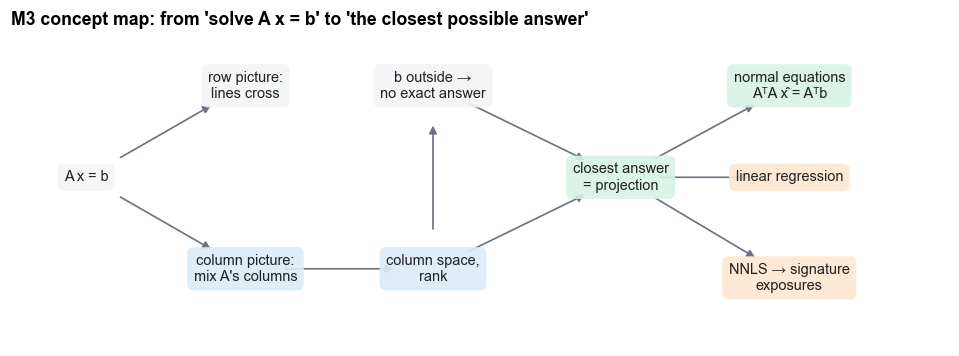

In [2]:
draw_concept_map_m3()

**그림에서 볼 것**
- Ax = b 를 행으로 보면 "직선(평면)들의 교점", 열로 보면 "열을 섞어 b 만들기" 입니다. 이 노트북은 주로 열 그림을 씁니다.
- b 가 열 공간 밖에 있으면 정확한 답이 없고, 그때 가장 가까운 답이 투영입니다. 회귀와 signature 노출량 추정(NNLS)이 모두 여기서 나옵니다.

## 1. Ax = b: 행 그림과 열 그림

**한 줄 정의**: Ax = b 는 "A 의 열을 각각 몇 번 쓰면(x) b 가 되나"를 묻는 식입니다. 행으로 읽으면 식 하나하나가 직선이고, 답은 직선들이 만나는 점입니다.

**왜 필요한가**: 행 그림은 미지수가 2~3개일 때만 그릴 수 있지만, 열 그림은 차원이 커져도 같은 말("열을 섞어 b 를 만든다")로 남습니다. 최소제곱은 열 그림에서만 자연스럽게 보입니다.

**숫자로 따라가기**: 2x + y = 5, x + 3y = 5 의 답은 (2, 1) 입니다. 열로 쓰면 2 × (2, 1) + 1 × (1, 3) = (5, 5) = b 입니다.

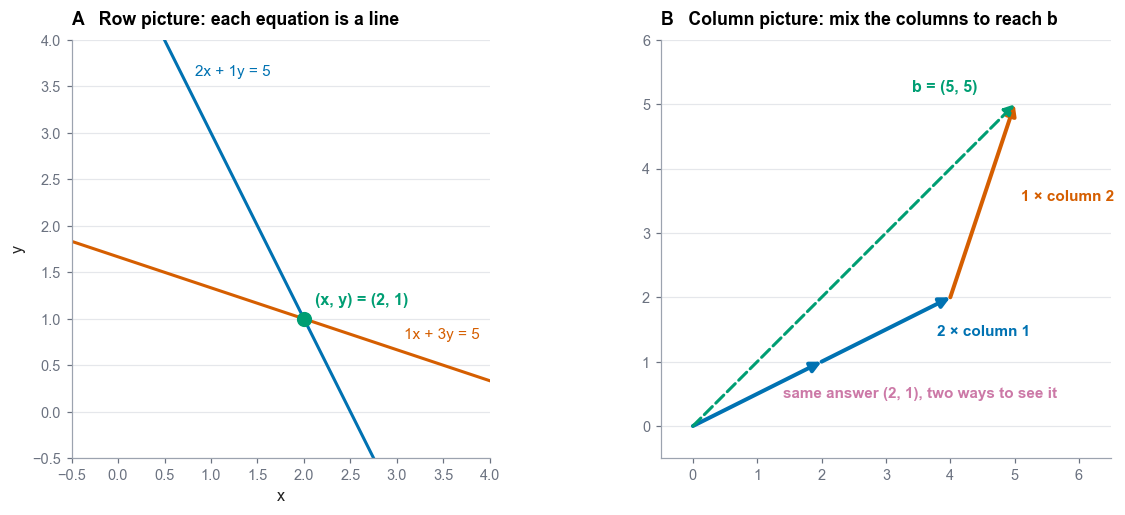

In [3]:
x_sol = draw_row_column_pictures()

**그림에서 볼 것**
- A: 파란 직선(첫째 식)과 빨간 직선(둘째 식)이 초록 점 (2, 1) 에서 만납니다.
- B: 파란 1열 (2, 1) 을 두 번, 빨간 2열 (1, 3) 을 한 번 이으면 초록 점선 b = (5, 5) 에 닿습니다. 걸음 수 (2, 1) 이 A 의 답과 같습니다.

**수식 풀어 읽기**

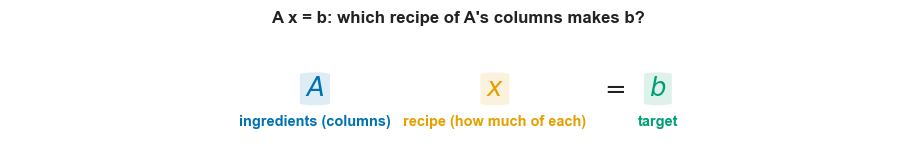

In [4]:
show_formula([(r"$A$", COL["e1"], "ingredients (columns)"), (r"$x$", COL["extra"], "recipe (how much of each)"),
              (r"$=$", None, None), (r"$b$", COL["result"], "target")],
             title="A x = b: which recipe of A's columns makes b?")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $A$ | "A" | 열들이 재료 | B 의 파랑·빨강 화살표 |
| $x$ | "x" | 열마다 몇 번 쓸지(조리법) | B 의 2 번, 1 번 |
| $b$ | "b" | 만들고 싶은 목표 | B 의 초록 점선 |

In [5]:
A0 = np.array([[2.0, 1.0], [1.0, 3.0]]); b0 = np.array([5.0, 5.0])
assert np.allclose(x_sol, [2, 1]) and np.allclose(A0 @ x_sol, b0)
assert np.allclose(x_sol[0] * A0[:, 0] + x_sol[1] * A0[:, 1], b0)
print("답 x =", x_sol)

답 x = [2. 1.]


## 2. 열 공간과 rank: 만들 수 있는 b 의 범위

**한 줄 정의**
- 열 공간은 A 의 열을 어떻게든 섞어 만들 수 있는 모든 벡터의 모임입니다.
- 어떤 열이 **나머지 열들을 섞어 만들 수 있으면** 그 열은 "종속"이고 새 방향을 더하지 못합니다(한 열의 배수인 경우뿐 아니라, 여러 열의 조합인 경우도 포함).
- rank 는 "서로 다른 열로는 만들 수 없는(독립인) 열을 가장 많이 고르면 몇 개인가"입니다. 열 공간의 차원과 같습니다.

**왜 필요한가**: b 가 열 공간 안에 있어야 답이 있습니다. 종속인 열은 새 방향을 더하지 못해, 열 수가 많아도 rank 와 만들 수 있는 범위는 그대로입니다.

**숫자로 따라가기**: 3차원에서 열이 2개(3 × 2 행렬)면 섞어 만들 수 있는 것은 많아야 **평면** 하나입니다. 3차원의 b 대부분은 그 평면 밖에 있습니다.

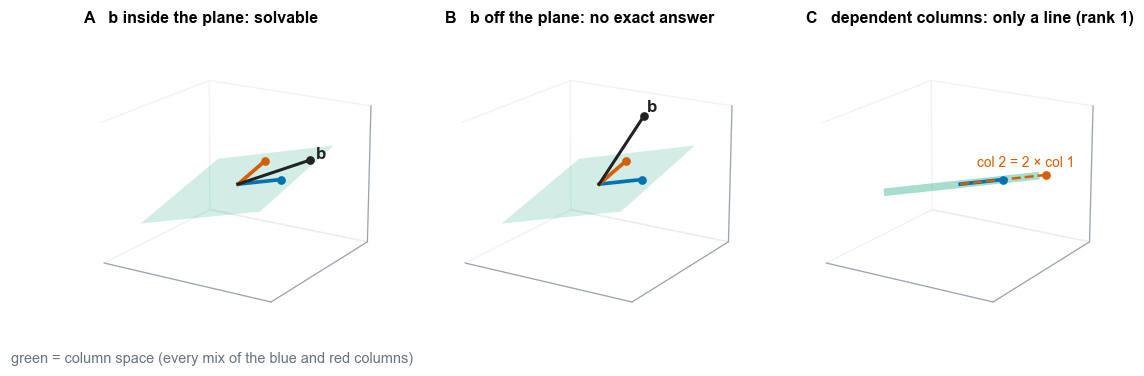

In [6]:
draw_column_space()

**그림에서 볼 것**
- A: 파란·빨간 열이 펼치는 초록 평면 안에 b 가 있어 정확히 만들 수 있습니다.
- B: b 가 평면 위로 튀어나와 있습니다. 두 열을 어떻게 섞어도 평면을 떠날 수 없으니 정확한 답이 없습니다.
- C: 둘째 열이 첫째 열의 2 배라 새 방향이 없습니다. 만들 수 있는 것은 초록 **직선**뿐이고 rank 는 1 입니다.

배수만 종속인 것이 아닙니다. 아래 셀의 세 번째 예는 셋째 열이 첫째와 둘째 열의 **합**이라, 열이 3 개여도 같은 평면에 갇혀 rank 가 2 입니다.

In [7]:
C3 = np.array([[1.0, 0.1], [0.2, 1.0], [0.3, 0.4]]); C3dep = np.column_stack([C3[:, 0], 2 * C3[:, 0]])
C3plane = np.column_stack([C3[:, 0], C3[:, 1], C3[:, 0] + C3[:, 1]])     # 셋째 열 = 첫째 + 둘째: 열은 3 개, 방향은 2 개
assert np.linalg.matrix_rank(C3) == 2 and np.linalg.matrix_rank(C3dep) == 1 and np.linalg.matrix_rank(C3plane) == 2
print("rank(독립인 두 열) =", np.linalg.matrix_rank(C3), "  rank(2배인 두 열) =", np.linalg.matrix_rank(C3dep),
      "  rank(셋째 열 = 첫째 + 둘째) =", np.linalg.matrix_rank(C3plane))

rank(독립인 두 열) = 2   rank(2배인 두 열) = 1   rank(셋째 열 = 첫째 + 둘째) = 2


> **시퀀싱 데이터에서는** 96칸 catalogue 는 96차원 벡터인데 signature 는 몇 개뿐이라, 실제 catalogue 는 잡음 때문에 거의 늘 signature 들이 펼치는 공간 **밖**에 있습니다. 그래서 노출량은 "정확한 답"이 아니라 아래의 "가장 가까운 답"으로 구합니다.

## 3. 답이 없을 때: 가장 가까운 점은 직각으로 떨어뜨린 그림자

**한 줄 정의**: 열 공간 안에서 b 에 가장 가까운 점 p 는 b 에서 평면으로 **수직으로** 내린 발이고, 그때의 오차 e = b − p 는 평면의 모든 방향과 직각입니다(이 노트북의 아래 확인).

**왜 필요한가**: "가장 가깝다"를 "오차의 길이 $\lVert b - Ax\rVert$ 가 가장 작다"로 정하면(최소제곱), 답이 하나로 정해지고 계산 공식이 생깁니다.

**숫자로 따라가기**: 직각삼각형에서 빗변이 가장 깁니다. 평면 위 다른 점 q 까지의 거리는 $\sqrt{\lVert e\rVert^2 + \lVert p - q\rVert^2}$ 라 늘 $\lVert e\rVert$ 보다 깁니다.

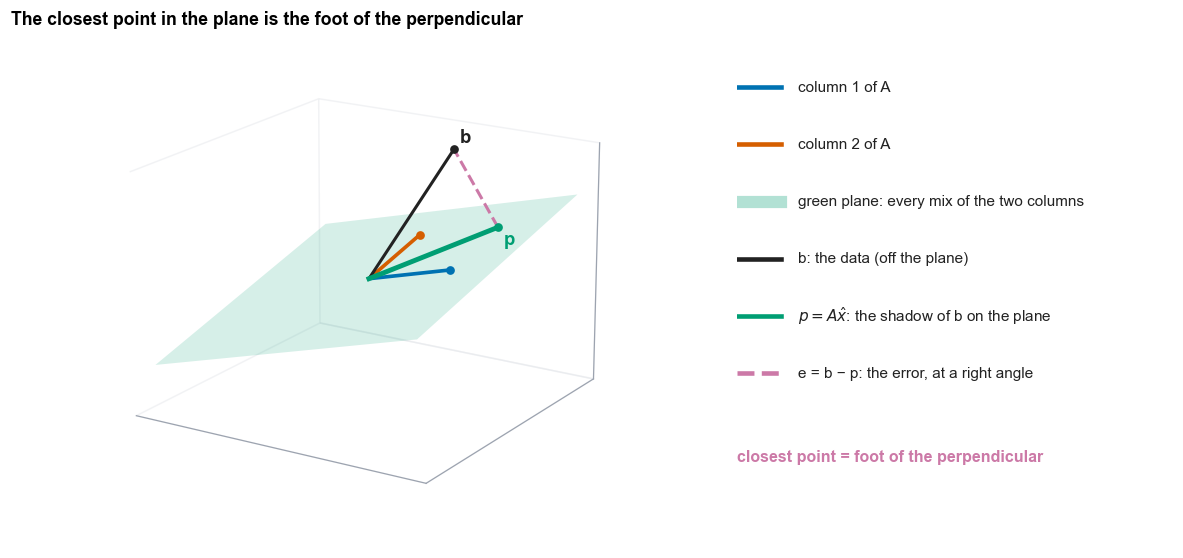

In [8]:
A3d, b3d, xh3d, p3d, e3d = draw_projection_3d()

**그림에서 볼 것**
- 검은 b 에서 자주색 점선(오차 e)을 평면에 수직으로 내린 곳이 초록 p 입니다.
- p 는 평면 안에 있으므로 파란·빨간 열을 섞어 만들 수 있고, 그 섞는 양이 최소제곱 답 x̂ 입니다.

In [9]:
assert np.allclose(A3d.T @ e3d, 0)               # 오차는 두 열과 모두 직각
rng = np.random.default_rng(0)
others = A3d @ rng.normal(size=(2, 2000)) + p3d[:, None] * 0
dist_others = np.linalg.norm(b3d[:, None] - others, axis=0)
assert dist_others.min() >= np.linalg.norm(e3d) - 1e-9
print(f"|e| = {np.linalg.norm(e3d):.3f},  평면 위 무작위 2000점 중 가장 가까운 거리 = {dist_others.min():.3f}")

|e| = 1.523,  평면 위 무작위 2000점 중 가장 가까운 거리 = 1.524


## 4. 직각 조건에서 정규방정식이 나온다

**한 줄 정의**: 오차 e = b − A x̂ 가 A 의 모든 열과 직각이라는 조건 $A^\top (b - A\hat x) = 0$ 을 정리하면 **정규방정식** $A^\top A\,\hat x = A^\top b$ 입니다(아래 유도는 이 노트북에서 한 것).

**왜 필요한가**: 직각 조건은 그림의 말이고, 정규방정식은 그것을 계산할 수 있는 식으로 바꾼 것입니다. $A^\top A$ 는 작은 정사각 행렬(열 수 × 열 수)이라 풀기 쉽습니다.

**유도** (이 노트북에서 한 줄씩)
1. e 가 A 의 열 $a_j$ 와 직각이면 $a_j \cdot e = 0$ (M1 의 "내적 0 = 직각").
2. 모든 열에 대해 한꺼번에 쓰면 $A^\top e = 0$ ($A^\top$ 의 행 = A 의 열, M2 의 전치).
3. $e = b - A\hat x$ 를 넣으면 $A^\top b - A^\top A \hat x = 0$, 즉 $A^\top A \hat x = A^\top b$.

**수식 풀어 읽기**

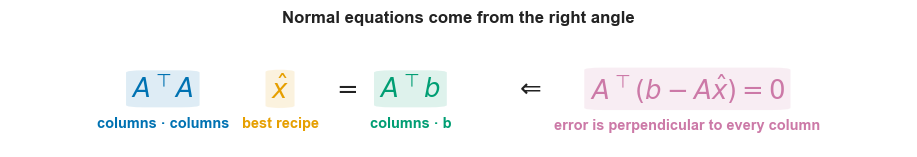

In [10]:
show_formula([(r"$A^\top A$", COL["e1"], "columns · columns"), (r"$\hat{x}$", COL["extra"], "best recipe"),
              (r"$=$", None, None), (r"$A^\top b$", COL["result"], "columns · b"), (r"$\qquad\Leftarrow\qquad$", None, None),
              (r"$A^\top(b - A\hat{x}) = 0$", COL["highlight"], "error is perpendicular to every column")],
             title="Normal equations come from the right angle")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\hat x$ | "x 햇" | 최소제곱 답(가장 가까운 조리법) | p 를 만드는 섞는 양 |
| $A^\top A$ | "A 전치 A" | 열끼리의 내적 표 | - |
| $A^\top b$ | "A 전치 b" | 열마다 b 와의 내적 | - |
| $A^\top(b - A\hat x) = 0$ | "오차와 모든 열의 내적이 0" | 오차가 평면과 직각 | 자주색 점선 ⟂ 초록 평면 |

**기호 사전**: ⟂ = "직각이다(내적이 0)". $\lVert v\rVert^2$ = "v 의 길이의 제곱".

**숫자로 따라가기**: 점 (0, 6), (1, 0), (2, 0) 을 지나는 직선 y = C + D t 를 찾는다고 하면, A = [[1, 0], [1, 1], [1, 2]], b = (6, 0, 0) 입니다.

| | 계산 | 값 |
|---|---|---|
| $A^\top A$ | [[1+1+1, 0+1+2], [0+1+2, 0+1+4]] | [[3, 3], [3, 5]] |
| $A^\top b$ | [6+0+0, 0+0+0] | [6, 0] |
| $\hat x$ | 3C + 3D = 6, 3C + 5D = 0 를 풀면 | C = 5, D = −3 |
| $p = A\hat x$ | 5 − 3t 에 t = 0, 1, 2 | (5, 2, −1) |
| $e = b - p$ | (6−5, 0−2, 0+1) | (1, −2, 1) |

마지막 줄의 e 는 A 의 두 열 (1, 1, 1), (0, 1, 2) 와 내적이 모두 0 입니다: 1 − 2 + 1 = 0, 0 − 2 + 2 = 0.

In [11]:
A_l = np.array([[1, 0], [1, 1], [1, 2]], float); b_l = np.array([6, 0, 0], float)
xh_l = np.linalg.solve(A_l.T @ A_l, A_l.T @ b_l)
assert np.allclose(A_l.T @ A_l, [[3, 3], [3, 5]]) and np.allclose(A_l.T @ b_l, [6, 0])
assert np.allclose(xh_l, [5, -3]) and np.allclose(b_l - A_l @ xh_l, [1, -2, 1])
assert np.allclose(xh_l, np.linalg.lstsq(A_l, b_l, rcond=None)[0])
print("x̂ =", xh_l, "  e =", b_l - A_l @ xh_l, "  numpy lstsq 와 같음")

x̂ = [ 5. -3.]   e = [ 1. -2.  1.]   numpy lstsq 와 같음


### 답이 하나뿐인가

**한 줄 정의**: $A^\top A$ 에 역행렬이 있으면 x̂ 는 하나뿐이고, 그 조건은 **A 의 열이 서로 독립(rank = 열 수)** 인 것입니다(이 노트북에서 확인).

**왜 필요한가**: 열이 종속이면(2절 그림 C) 그림자 p 자체는 하나로 정해지지만, p 를 만드는 섞는 양 x̂ 는 여러 가지입니다. 예를 들어 둘째 열이 첫째 열의 2 배면 "첫째 열 2 번"과 "둘째 열 1 번"이 같은 점을 만듭니다. 이때 $A^\top A$ 는 행렬식이 0 이라 역행렬이 없습니다(M2 7절).

**숫자로 따라가기**: 아래에서 독립인 열(rank 2)은 $\det(A^\top A) \ne 0$ 이고, 2 배인 열(rank 1)은 $\det(A^\top A) = 0$ 이며 서로 다른 x 두 개가 같은 Ax 를 만듭니다.

In [12]:
for name_, M_ in [("독립인 두 열", C3), ("2배인 두 열", C3dep)]:
    print(f"{name_}: rank = {np.linalg.matrix_rank(M_)}, det(AᵀA) = {np.linalg.det(M_.T @ M_):.4f}")
assert not np.isclose(np.linalg.det(C3.T @ C3), 0) and np.isclose(np.linalg.det(C3dep.T @ C3dep), 0)
xa, xb = np.array([2.0, 0.0]), np.array([0.0, 1.0])
assert np.allclose(C3dep @ xa, C3dep @ xb) and not np.allclose(xa, xb)
print("2배인 열: x = (2, 0) 과 (0, 1) 이 같은 Ax 를 만듦 → 섞는 양은 하나로 안 정해짐")

독립인 두 열: rank = 2, det(AᵀA) = 1.1457
2배인 두 열: rank = 1, det(AᵀA) = 0.0000
2배인 열: x = (2, 0) 과 (0, 1) 이 같은 Ax 를 만듦 → 섞는 양은 하나로 안 정해짐


## 5. 선형 회귀 = 최소제곱

**한 줄 정의**: 점들에 직선(또는 평면)을 맞추는 선형 회귀는 "세로 오차의 제곱합이 가장 작은 직선"이고, 그것이 바로 위의 정규방정식의 답입니다.

**왜 필요한가**: 회귀를 "통계 기법"으로만 외우면 공식이 따로 노는 것 같지만, 행렬로 보면 "b 를 A 의 열 공간에 투영하기" 한 가지입니다.

**숫자로 따라가기**: 4절의 세 점에 대해 최선의 직선은 y = 5 − 3t 이고, 세로 오차는 +1, −2, +1 입니다. 제곱합은 1 + 4 + 1 = 6 입니다.

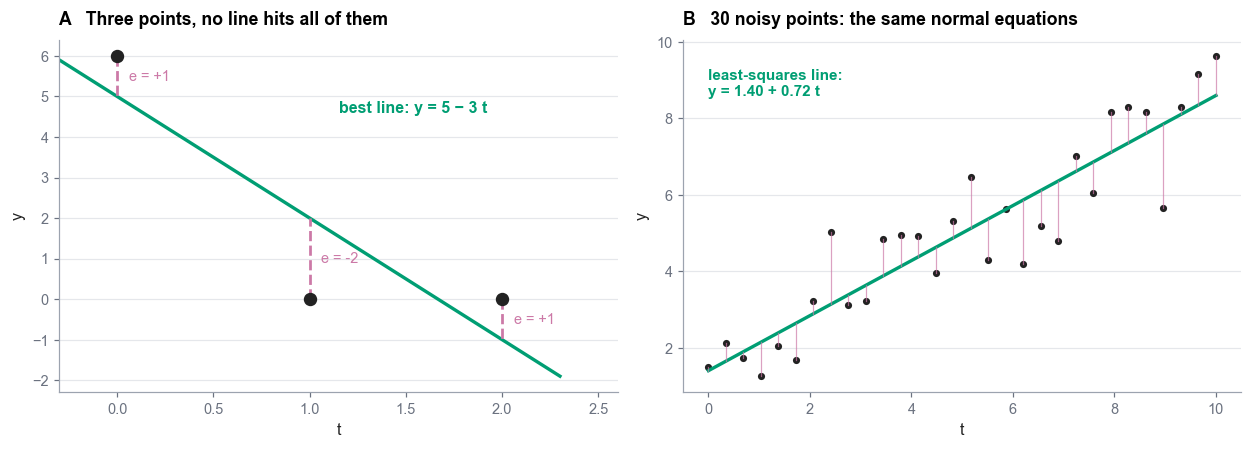

In [13]:
A_l, y_l, xh_line, xh_30, (A30, Y30) = draw_line_fit()

**그림에서 볼 것**
- A: 어떤 직선도 세 점을 다 지나지 않습니다. 초록 직선은 자주색 세로 오차 세 개의 제곱합이 가장 작은 직선입니다.
- B: 점이 30 개여도 계산은 같습니다. A 의 열이 (1, 1, …, 1) 과 (t₁, t₂, …) 두 개이고, 같은 정규방정식을 풉니다.

In [14]:
sse = lambda c, d: np.sum((y_l - (c + d * A_l[:, 1])) ** 2)
assert np.isclose(sse(*xh_line), 6.0)
assert all(sse(*xh_line) <= sse(xh_line[0] + dc, xh_line[1] + dd) for dc in (-0.3, 0, 0.3) for dd in (-0.3, 0, 0.3))
assert np.allclose(xh_30, np.polyfit(A30[:, 1], Y30, 1)[::-1])
print("오차 제곱합 =", sse(*xh_line), "/ 30점 직선 = numpy polyfit 과 같음:", np.round(xh_30, 3))

오차 제곱합 = 6.0 / 30점 직선 = numpy polyfit 과 같음: [1.404 0.72 ]


**직접 바꿔 보기**: `draw_line_fit(t=(0, 1, 2, 3), yv=(1, 2, 2, 5))` 로 점을 바꿔 보세요.

In [15]:
# draw_line_fit(t=(0, 1, 2, 3), yv=(1, 2, 2, 5))

## 6. 계수가 음수일 수 없을 때: NNLS

**한 줄 정의**: NNLS(non-negative least squares, 음수 없는 최소제곱)는 $\lVert Ax - b\rVert^2$ 를 가장 작게 하되 **x 의 모든 칸이 0 이상**이어야 한다는 조건을 붙인 최소제곱입니다 [3].

**왜 필요한가**: 노출량(어떤 signature 가 만든 변이 수)이나 성분의 양은 음수일 수 없습니다. 보통 최소제곱은 잡음을 맞추려고 음수 계수를 내기도 하는데, 그런 답은 해석할 수 없습니다.

**수식 풀어 읽기**

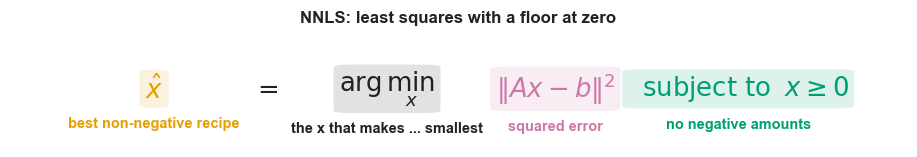

In [16]:
show_formula([(r"$\hat{x}$", COL["extra"], "best non-negative recipe"), (r"$=$", None, None),
              (r"$\arg\min_{x}$", COL["ink"], "the x that makes ... smallest"),
              (r"$\| A x - b \|^2$", COL["highlight"], "squared error"),
              (r"$\;\;\mathrm{subject\ to}\;\; x \geq 0$", COL["result"], "no negative amounts")],
             title="NNLS: least squares with a floor at zero")

| 기호 | 소리 내어 읽기 | 뜻 | 그림에서 어디 |
|---|---|---|---|
| $\arg\min_x$ | "아그민 x" | 뒤의 값을 가장 작게 만드는 x | - |
| $\lVert Ax - b\rVert^2$ | "오차 길이의 제곱" | 맞춘 것과 관측의 차이 | 아래 그림 B 의 막대와 선 차이 |
| $x \ge 0$ | "x 가 0 이상" | 모든 노출량이 음수가 아님 | 그림 C 의 초록 마름모 |

**기호 사전**: $\arg\min$ = "최소가 되는 값 자체(최솟값이 아니라 그때의 x)".

## 7. 응용: 이미 아는 signature 로 표본 하나의 노출량 구하기

**한 줄 정의**: 표본 하나의 96칸 catalogue v 를 signature 행렬 P(96 × N) 의 열들로 설명하는 노출량 a 를 NNLS 로 구합니다. $v \approx P a$, $a \ge 0$.

**왜 필요한가**: 이것이 signature "assignment(배정)" 입니다. Alexandrov 등은 catalogue 를 M ≈ P × E 로 모형화했고 [5], SigProfilerAssignment 는 signature 를 고르는 forward stagewise 알고리즘과 Lawson–Hanson 방식의 NNLS 를 계산 엔진으로 씁니다 [4].

**숫자로 따라가기**: 아래는 **장난감 signature 4 개**(COSMIC signature 가 아님)입니다. 96칸은 염기 치환 6 종류 × 앞뒤 염기 16 조합입니다 [6]. 표본 하나를 노출량 (300, 0, 150, 50) 으로 만들고 포아송 잡음을 넣은 뒤, 노출량을 거꾸로 구합니다.

**용어 사전**
- 포아송 잡음: 개수를 셀 때 생기는 우연한 흔들림. 평균이 λ 인 칸은 매번 λ 근처의 정수가 나오고, 흔들림의 분산도 λ 입니다(`rng.poisson`).
- Lawson–Hanson: NNLS 를 푸는 고전적인 방법(active set 방법). Lawson 과 Hanson 의 책에 FORTRAN 코드가 실렸고, 이 PC 의 SciPy 1.11.4 `nnls` 가 그 코드를 감싼 것입니다 [3].
- forward stagewise: SigProfilerAssignment 논문이 자기 선택 단계를 부르는 이름입니다(Hastie 등 2009 를 인용) [4]. 실제 동작은 아래 "후보가 너무 많으면" 에서 봅니다.

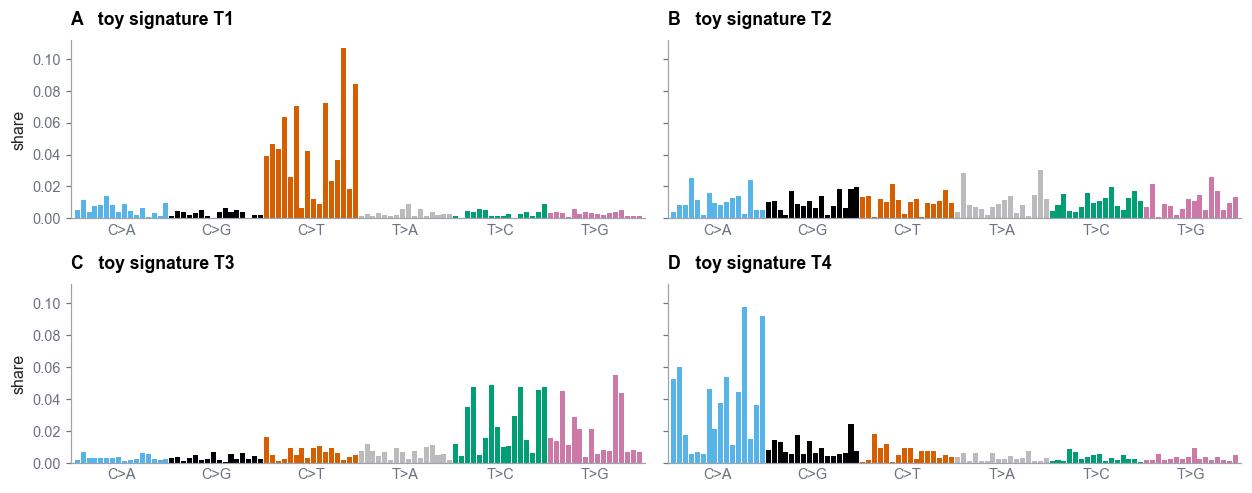

In [17]:
P8 = toy_signatures(); names8 = [f"T{i + 1}" for i in range(8)]
P = P8[:, :4]; names = names8[:4]
draw_signatures(P, names)

**그림에서 볼 것**
- 막대 색은 96칸 그림에서 흔히 쓰는 6 가지 치환 종류의 구분입니다(이 그림에서만 쓰는 색이고, 파랑·빨강이 e1·e2 를 뜻하지 않습니다).
- T1 은 C>T, T3 는 T>C·T>G, T4 는 C>A 가 많고, T2 는 고른 편입니다. 각 signature 의 96칸 합은 1 입니다.

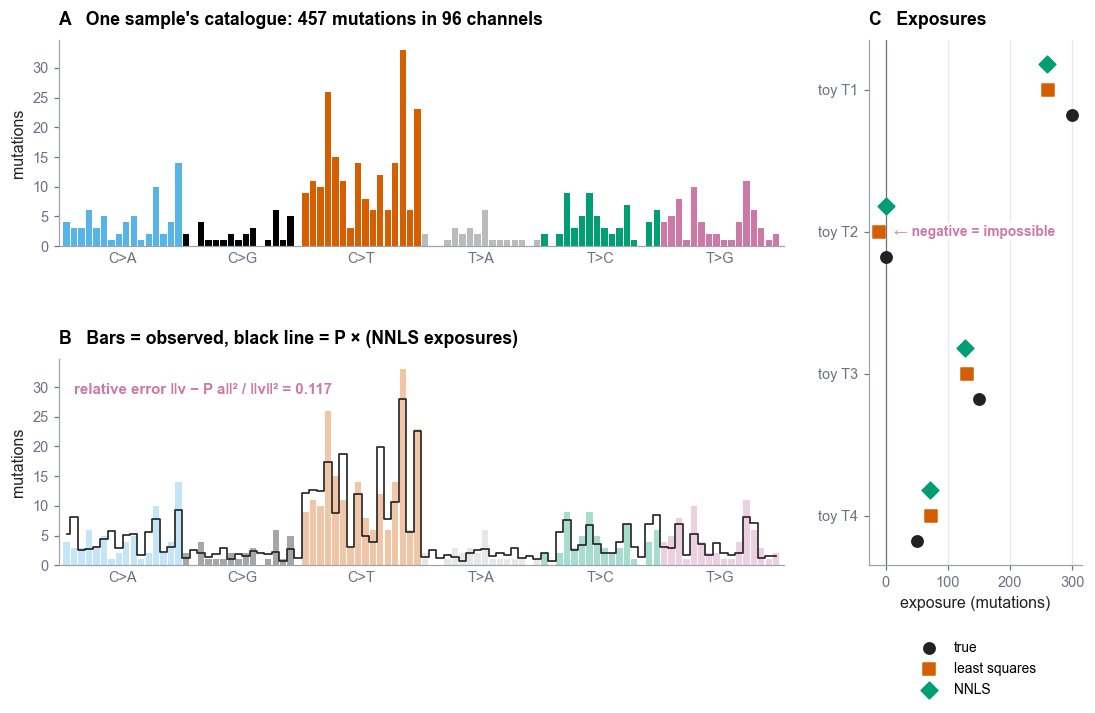

In [18]:
rng = np.random.default_rng(5)
ex_true = np.array([300.0, 0.0, 150.0, 50.0])
v = rng.poisson(P @ ex_true).astype(float)
ex_ls = np.linalg.lstsq(P, v, rcond=None)[0]
ex_nnls, _ = nnls(P, v)
rel = draw_fit_sample(P, v, ex_true, ex_ls, ex_nnls, names)

**그림에서 볼 것**
- A: 장난감 표본의 catalogue 입니다. 노출량 300 인 T1 때문에 C>T(빨간 막대)가 가장 많습니다.
- B: 옅은 막대가 관측, 검은 선이 NNLS 노출량으로 다시 만든 P × a 입니다. 상대 오차는 SigProfilerAssignment 알고리즘이 쓰는 것과 같은 꼴 $\lVert v - Pa\rVert^2 / \lVert v\rVert^2$ 입니다 [4].
- C: 검은 점(진짜), 빨간 네모(보통 최소제곱), 초록 마름모(NNLS) 입니다. 진짜 0 인 T2 에서 보통 최소제곱은 이 실행에서 약 −11.5 라는 **음수**를 냈고(자주색 글씨), NNLS 는 0 입니다.

In [19]:
assert np.all(ex_nnls >= 0) and ex_ls[1] < 0 and np.isclose(ex_ls[1], -11.5, atol=0.1) and ex_nnls[1] == 0
assert np.isclose(rel, np.sum((v - P @ ex_nnls) ** 2) / np.sum(v ** 2))
assert np.abs(ex_nnls - ex_true).max() < 60
print("진짜 노출량   :", ex_true)
print("최소제곱      :", np.round(ex_ls, 1))
print("NNLS          :", np.round(ex_nnls, 1))

진짜 노출량   : [300.   0. 150.  50.]
최소제곱      : [260.7 -11.5 131.1  72.6]
NNLS          : [259.1   0.  126.9  71. ]


### 후보 signature 가 너무 많으면

**한 줄 정의**: 후보가 많을수록 NNLS 는 잡음을 맞추려고 **쓰이지 않은 signature 에도 조금씩** 노출량을 나눠 줍니다.

**왜 필요한가**: 그래서 실제 도구는 **고르는 단계**를 둡니다. SigProfilerAssignment 논문은 이를 "a custom implementation of the forward stagewise algorithm" 이라 부르고, Algorithm 1 의 실제 순서는 이렇습니다 [4].
1. 모든 후보 signature 로 NNLS 를 풀어 상대 오차 $\epsilon = \lVert v - Sa\rVert_2^2 / \lVert v\rVert_2^2$ (**제곱**끼리의 비)를 잽니다.
2. **빼기**: signature 를 하나씩 빼 보고, 가장 덜 나빠지는 것을 뺐을 때 오차가 0.01 이하로만 늘면 뺍니다.
3. **더하기**: 빠진 signature 를 하나씩 더해 보고, 가장 좋아지는 것이 오차를 0.05 이상 줄이면 더합니다.
4. 더 빼거나 더할 것이 없을 때까지 2–3 을 되풀이하고, 남은 signature 로 NNLS 를 한 번 더 풉니다.

**숫자로 따라가기**: 후보 8 개 중 3 개만 쓴(T2 는 노출량 0) 표본에 대해, (가) 8 개를 다 넣은 NNLS 와 (나) 위 1–4 를 그대로 옮긴 장난감 구현을 비교합니다. (나) 는 논문의 의사코드를 따라 짠 것이라 실제 패키지 코드의 세부(오차를 갱신하는 시점 등)와는 다를 수 있습니다.

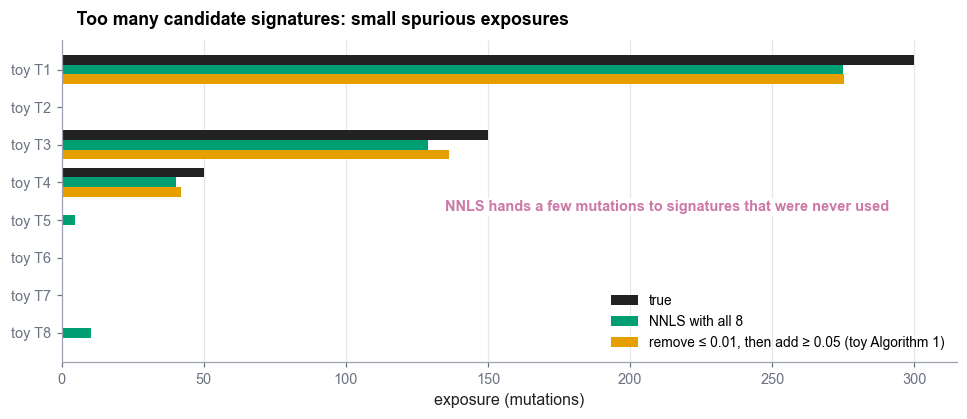

In [20]:
ex_true8 = np.array([300.0, 0, 150, 50, 0, 0, 0, 0])
v8 = rng.poisson(P8 @ ex_true8).astype(float)
ex_all8, _ = nnls(P8, v8)


def rel_err(P_, v_, idx):
    """선택한 signature 들로 NNLS 를 풀고 상대 오차 ‖v − Sa‖² / ‖v‖² (제곱끼리의 비)"""
    a_, _ = nnls(P_[:, idx], v_)
    return np.sum((v_ - P_[:, idx] @ a_) ** 2) / np.sum(v_ ** 2)


def remove_then_add(P_, v_, rm_tol=0.01, add_gain=0.05):
    """SigProfilerAssignment Algorithm 1 의 뼈대를 옮긴 장난감: 모두 넣고 시작 → 빼기(≤ 0.01) → 더하기(≥ 0.05) 반복"""
    S = list(range(P_.shape[1])); e_min = rel_err(P_, v_, S)
    changed = True
    while changed:
        changed = False
        while len(S) > 1:                                   # 빼기
            val, r = min((rel_err(P_, v_, [j for j in S if j != r]), r) for r in S)
            if val - e_min <= rm_tol:
                S.remove(r); e_min = val; changed = True
            else:
                break
        while len(S) < P_.shape[1]:                         # 더하기
            val, q = min((rel_err(P_, v_, S + [q]), q) for q in range(P_.shape[1]) if q not in S)
            if e_min - val >= add_gain:
                S.append(q); e_min = val; changed = True
            else:
                break
    a_full = np.zeros(P_.shape[1]); S = sorted(S)
    a_full[S] = nnls(P_[:, S], v_)[0]
    return a_full, S


ex_fwd, chosen = remove_then_add(P8, v8)
draw_sparsity(names8, ex_true8, ex_all8, ex_fwd)

**그림에서 볼 것**
- 검은 막대가 진짜 노출량(T1, T3, T4 만 0 보다 큼, T2 는 0)입니다.
- 초록(NNLS, 후보 8 개)은 쓰이지 않은 signature 몇 개에도 작은 막대를 줍니다.
- 주황(빼고 더하기, 위 1–4)은 빼도 오차가 거의 늘지 않는 signature 를 빼서, 진짜로 쓰인 T1, T3, T4 만 남깁니다. 이 결과는 이 노트북의 장난감 구현과 이 시뮬레이션에 대한 것입니다.

In [21]:
print("NNLS(8개) 가 0 보다 크게 준 signature:", [names8[i] for i in np.where(ex_all8 > 0.5)[0]])
print("빼고 더하기가 남긴 signature        :", [names8[i] for i in chosen])
assert set(np.where(ex_true8 > 0)[0]) == {0, 2, 3}
assert set(chosen) == {0, 2, 3}                                   # 진짜로 쓰인 것만 남김
assert len(set(np.where(ex_all8 > 0.5)[0]) - {0, 2, 3}) >= 1     # 8 개 NNLS 는 쓰이지 않은 것에도 노출량을 줌

NNLS(8개) 가 0 보다 크게 준 signature: ['T1', 'T3', 'T4', 'T5', 'T8']
빼고 더하기가 남긴 signature        : ['T1', 'T3', 'T4']


> **실제 도구와 다른 점**: 이 노트북의 signature 는 만든 장난감입니다. 선택 단계는 논문 Algorithm 1 의 순서와 문턱값(빼기 0.01, 더하기 0.05)을 옮겼지만, 실제 패키지에는 그 밖의 설정과 세부가 더 있고(논문 보충 자료) [4], 여기서는 그것까지 재현하지 않았습니다.

## 연습 문제

1. x + y = 2, x − y = 0 의 답은? 열 그림으로는 무엇을 뜻하나요?
2. A 의 열이 (1, 2, 3) 과 (2, 4, 6) 이면 rank 는?
3. 점 (0, 1), (1, 1), (2, 4) 에 직선을 맞출 때의 $A^\top A$ 와 $A^\top b$ 는?
4. 노출량 추정에 보통 최소제곱 대신 NNLS 를 쓰는 이유는?

<details><summary>정답 보기</summary>

1. (1, 1). 1 × (1, 1) + 1 × (1, −1) = (2, 0) = b 라는 뜻입니다.
2. 1. 둘째 열이 첫째 열의 2 배라 새 방향이 없습니다.
3. A = [[1, 0], [1, 1], [1, 2]], b = (1, 1, 4) 이므로 $A^\top A$ = [[3, 3], [3, 5]], $A^\top b$ = [6, 9]. 풀면 C = 0.5, D = 1.5.
4. 노출량은 음수일 수 없습니다. 보통 최소제곱은 잡음을 맞추려고 음수를 낼 수 있어 해석이 안 됩니다.

</details>

In [22]:
assert np.allclose(np.linalg.solve([[1, 1], [1, -1]], [2, 0]), [1, 1])
assert np.linalg.matrix_rank(np.array([[1, 2], [2, 4], [3, 6]])) == 1
A_q = np.array([[1, 0], [1, 1], [1, 2]], float); b_q = np.array([1, 1, 4], float)
assert np.allclose(A_q.T @ A_q, [[3, 3], [3, 5]]) and np.allclose(A_q.T @ b_q, [6, 9])
assert np.allclose(np.linalg.solve(A_q.T @ A_q, A_q.T @ b_q), [0.5, 1.5])

## 정리

- Ax = b 는 "A 의 열로 b 를 만드는 조리법 x 찾기" 입니다. 만들 수 있는 범위가 열 공간이고, 독립인 방향 수가 rank 입니다.
- b 가 열 공간 밖이면 정확한 답이 없고, 가장 가까운 점은 수직으로 떨어뜨린 그림자 p 입니다. 오차는 모든 열과 직각입니다.
- 그 직각 조건 $A^\top(b - A\hat x) = 0$ 이 정규방정식 $A^\top A\hat x = A^\top b$ 이고, 선형 회귀가 바로 이것입니다.
- 계수가 음수일 수 없으면 NNLS 를 씁니다. 이미 아는 signature 로 노출량을 구하는 signature assignment 가 이 문제이고, 후보가 많을 때는 고르는 단계가 필요합니다.

## 출처

1. MIT OpenCourseWare, 18.06 Linear Algebra (Gilbert Strang), Spring 2010, Video Lectures 목록. https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/video_galleries/video-lectures/ — 머리의 "같이 볼 강의" 회차와 제목만 확인했습니다(Lecture 1·6·9·15·16). 본문의 정의·유도·숫자는 이 노트북에서 직접 한 것이고, 이 출처에 기대지 않습니다.
2. 3Blue1Brown (Grant Sanderson), "Essence of linear algebra" 재생목록. https://www.youtube.com/playlist?list=PLZHQObOWTQDPD3MizzM2xVFitgF8hE_ab — Chapter 2 "Linear combinations, span, and basis vectors", Chapter 7 "Inverse matrices, column space and null space" (장 제목 확인).
3. SciPy 문서, `scipy.optimize.nnls`. https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.nnls.html — "Solve argmin_x || Ax - b ||_2^2 for x>=0" (6절 정의). 이 노트북은 SciPy 1.11.4 로 실행했고, 이 판의 `nnls` 설명(docstring)은 "a wrapper for a FORTRAN non-negative least squares solver … published in the book below … an active set method", 참고문헌 Lawson & Hanson (1987) *Solving Least Squares Problems* 입니다(7절 용어 사전). SciPy 판에 따라 쓰는 알고리즘이 달라질 수 있습니다.
4. Díaz-Gay M, et al. (2023). Assigning mutational signatures to individual samples and individual somatic mutations with SigProfilerAssignment. *Bioinformatics* 39(12):btad756. doi:10.1093/bioinformatics/btad756, PMID 38096571. — "uses a custom implementation of the forward stagewise algorithm (Hastie et al. 2009) and it applies nonnegative least squares (NNLS), based on the Lawson-Hanson method"; Algorithm 1 의 순서(모든 signature 로 NNLS → removeSignatures → addSignatures 를 바뀌지 않을 때까지), 빼기 조건 "minValue − ϵmin ≤ 0.01", 더하기 조건 "ϵmin − minValue ≥ 0.05", 상대 오차 "ϵ = ‖v − Sa‖₂² / ‖v‖₂²" (7절).
5. Alexandrov LB, Nik-Zainal S, Wedge DC, Campbell PJ, Stratton MR (2013). Deciphering signatures of mutational processes operative in human cancer. *Cell Reports* 3(1):246–259. doi:10.1016/j.celrep.2012.12.008, PMID 23318258. — catalogue 모형 "M ≈ P × E" (Equation 3) (7절).
6. Alexandrov LB, et al. (2013). Signatures of mutational processes in human cancer. *Nature* 500:415–421. doi:10.1038/nature12477, PMID 23945592. — 6 가지 치환에 앞뒤 염기를 더해 "there are 96 possible mutations in this classification" (7절).